In [ ]:
import torchvision

train_set = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
test_set = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)

100%|██████████| 170M/170M [30:59<00:00, 91.7kB/s]


Kullanılan donanım: cuda
Epoch [1/3] | Loss: 0.4728 | Val Acc: 87.57%
Epoch [2/3] | Loss: 0.1154 | Val Acc: 87.13%
Epoch [3/3] | Loss: 0.0506 | Val Acc: 88.93%

Toplam Eğitim Süresi: 114.43 sn | En İyi Val Acc: 88.93%

--- RAPOR TABLOSU İÇİN TEST SONUÇLARI ---
Accuracy  : 89.23%
Precision : 89.20%
Recall    : 89.20%
F1-Score  : 89.13%


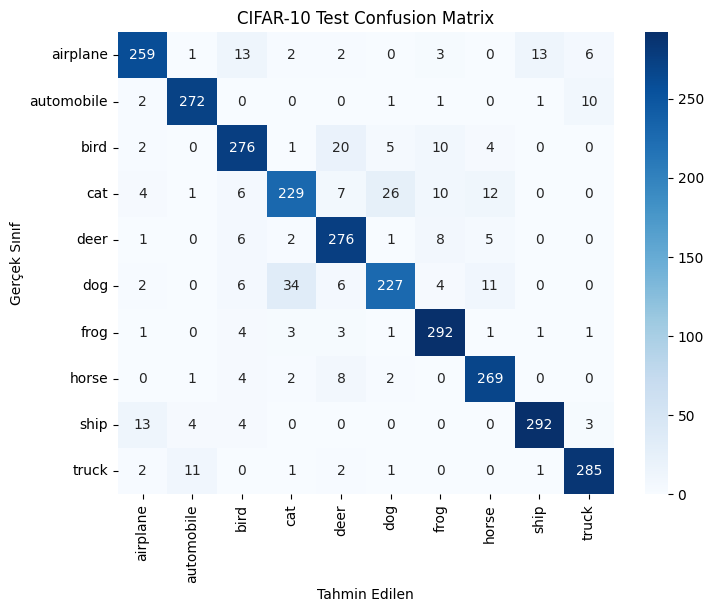

Ortalama Inference Time: 3.00 ms / görüntü


In [3]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from torchvision import models
from datasets import load_dataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. HuggingFace Sunucusundan 3 Saniyede İndirme
hf_ds = load_dataset("uoft-cs/cifar10")

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class HFCIFAR10(Dataset):
    def __init__(self, split, indices, transform=None):
        self.data = hf_ds[split].select(indices)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        img = item["img"].convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, item["label"]

# Hız ve yüksek doğruluk dengesi: 20.000 Train / 3.000 Val / 3.000 Test
train_dataset = HFCIFAR10("train", range(0, 20000), transform=transform)
val_dataset = HFCIFAR10("train", range(20000, 23000), transform=transform)
test_dataset = HFCIFAR10("test", range(0, 3000), transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

# 2. Model Kurulumu: İlk katmanları dondur, son blok (layer4) + fc eğit
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Kullanılan donanım: {device}")

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for name, param in model.named_parameters():
    if "layer4" in name or "fc" in name:
        param.requires_grad = True
    else:
        param.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, 10)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.0005, weight_decay=1e-4)

# 3. 3 Epoch Eğitim (~1.5 - 2 dakika)
epochs = 3
best_val_acc = 0.0
start_train_time = time.time()

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)

    model.eval()
    val_preds, val_targets = [], []
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            _, preds = torch.max(model(images), 1)
            val_preds.extend(preds.cpu().numpy())
            val_targets.extend(labels.numpy())

    val_acc = accuracy_score(val_targets, val_preds)
    print(f"Epoch [{epoch+1}/{epochs}] | Loss: {epoch_loss:.4f} | Val Acc: {val_acc*100:.2f}%")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_resnet18_cifar10.pth")

total_train_time = time.time() - start_train_time
print(f"\nToplam Eğitim Süresi: {total_train_time:.2f} sn | En İyi Val Acc: {best_val_acc*100:.2f}%")

# 4. Test Metrikleri ve Confusion Matrix
model.load_state_dict(torch.load("best_resnet18_cifar10.pth"))
model.eval()

test_preds, test_targets = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        _, preds = torch.max(model(images), 1)
        test_preds.extend(preds.cpu().numpy())
        test_targets.extend(labels.numpy())

acc = accuracy_score(test_targets, test_preds)
precision, recall, f1, _ = precision_recall_fscore_support(test_targets, test_preds, average='macro')

print("\n--- RAPOR TABLOSU İÇİN TEST SONUÇLARI ---")
print(f"Accuracy  : {acc*100:.2f}%")
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1-Score  : {f1*100:.2f}%")

classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
cm = confusion_matrix(test_targets, test_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Tahmin Edilen')
plt.ylabel('Gerçek Sınıf')
plt.title('CIFAR-10 Test Confusion Matrix')
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# 5. Tek Görüntü Inference Time
dummy_input = torch.randn(1, 3, 128, 128).to(device)
start_inf = time.time()
with torch.no_grad():
    for _ in range(100):
        _ = model(dummy_input)
avg_inference_ms = ((time.time() - start_inf) / 100) * 1000
print(f"Ortalama Inference Time: {avg_inference_ms:.2f} ms / görüntü")

In [ ]:
!pip install -q gradio

import gradio as gr
import torch.nn.functional as F
from PIL import ImageOps

classes = ['Airplane (Uçak)', 'Automobile (Otomobil)', 'Bird (Kuş)', 'Cat (Kedi)', 'Deer (Geyik)',
           'Dog (Köpek)', 'Frog (Kurbağa)', 'Horse (At)', 'Ship (Gemi)', 'Truck (Kamyon)']

def predict_image(img):
    if img is None:
        return None
    img = ImageOps.exif_transpose(img)  # Telefonun dik/yatay EXIF yönünü düzeltir
    img = img.convert("RGB")
    img_tensor = transform(img).unsqueeze(0).to(device)
    with torch.no_grad():
        outputs = model(img_tensor)
        probs = F.softmax(outputs[0], dim=0)
    return {classes[i]: float(probs[i]) for i in range(10)}

interface = gr.Interface(
    fn=predict_image,
    inputs=gr.Image(type="pil", label="Telefonla Çekilen Fotoğrafı Yükle"),
    outputs=gr.Label(num_top_classes=3, label="Model Tahmini"),
    title="CIFAR-10 Görüntü Sınıflandırma (ResNet-18)",
    description="Telefon kamerasıyla çekilen görüntünün ait olduğu sınıfı tahmin eder."
)

interface.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://0e792dcb96c1d72bd6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
